# Predictive Maintenance — Machine Failure & Failure Mode Prediction (AI4I 2020)

This notebook implements the end-to-end ML workflow for the **AI4I 2020 Predictive Maintenance** dataset:
1. **Binary task:** Predict whether a milling machine will fail (`machine_failure`), with a cost-optimal probability threshold ($\text{Cost}_{\text{FN}} = 10 \times \text{Cost}_{\text{FP}}$).
2. **Multi-label task:** Predict the probable failure mode(s) among `TWF`, `HDF`, `PWF`, and `OSF`.

All core transformations, pipelines, and evaluation utilities are imported from `src/pdm` so the notebook and `train.py` share a single source of truth.

In [1]:
# Papermill parameters cell
FAST = 0

In [2]:
# Parameters
FAST = 0


In [3]:
from __future__ import annotations

import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, average_precision_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score

from pdm.config import (
    COST_FN,
    COST_FP,
    DATA_PATH,
    MODE_COLS,
    RAW_FEATURE_COLS,
    SEED,
    TARGET_COL,
)
from pdm.data import load_raw, split_dataset
from pdm.evaluate import binary_metrics, choose_threshold, mode_metrics
from pdm.features import add_features
from pdm.pipeline import build_mode_pipeline, build_pipeline, get_model_candidates
from pdm.training import train_and_evaluate

sns.set_theme(style="whitegrid", context="notebook")
np.random.seed(SEED)
print(f"FAST mode: {bool(FAST)} | Dataset: {DATA_PATH}")

FAST mode: False | Dataset: /home/igorriegel/Documentos/Cursos/MLZoomcamp/ML_Zoomcamp_Midterm/data/ai4i2020.csv


## 1. Data Loading, Validation & Integrity Checks

In [4]:
df = load_raw(DATA_PATH)
print(f"Shape: {df.shape}")
print(f"Missing values: {int(df.isna().sum().sum())}")
print(f"Duplicate rows: {int(df.duplicated().sum())}")
print(f"Unique UDI: {df['udi'].nunique()} / {len(df)}")
df.head()

Shape: (10000, 14)
Missing values: 0
Duplicate rows: 0
Unique UDI: 10000 / 10000


,udi,product_id,type,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min,machine_failure,twf,hdf,pwf,osf,rnf
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
# Summary statistics for numeric sensors and targets
df.describe().T[["count", "mean", "std", "min", "50%", "max"]]

,count,mean,std,min,50%,max
udi,10000.0,5000.50000,2886.895680,1.0,5000.5,10000.0
air_temperature_k,10000.0,300.00493,2.000259,295.3,300.1,304.5
process_temperature_k,10000.0,310.00556,1.483734,305.7,310.1,313.8
rotational_speed_rpm,10000.0,1538.77610,179.284096,1168.0,1503.0,2886.0
torque_nm,10000.0,39.98691,9.968934,3.8,40.1,76.6
tool_wear_min,10000.0,107.95100,63.654147,0.0,108.0,253.0
machine_failure,10000.0,0.03390,0.180981,0.0,0.0,1.0
twf,10000.0,0.00460,0.067671,0.0,0.0,1.0
hdf,10000.0,0.01150,0.106625,0.0,0.0,1.0
pwf,10000.0,0.00950,0.097009,0.0,0.0,1.0


In [6]:
# Document label inconsistencies in the raw AI4I 2020 dataset:
# Some rows have machine_failure=1 with no specific failure mode flagged (or RNF=1 with machine_failure=0).
mode_any = df[MODE_COLS].max(axis=1)
inconsistent_pos = df[(df[TARGET_COL] == 1) & (mode_any == 0)]
inconsistent_neg = df[(df[TARGET_COL] == 0) & (mode_any == 1)]
print(f"machine_failure=1 but all TWF/HDF/PWF/OSF=0: {len(inconsistent_pos)} rows")
print(f"machine_failure=0 but at least one TWF/HDF/PWF/OSF=1: {len(inconsistent_neg)} rows")
print(f"RNF=1 count: {int(df['rnf'].sum())} (excluded from likely_modes per D2)")

machine_failure=1 but all TWF/HDF/PWF/OSF=0: 9 rows
machine_failure=0 but at least one TWF/HDF/PWF/OSF=1: 0 rows
RNF=1 count: 19 (excluded from likely_modes per D2)


## 2. Exploratory Data Analysis (EDA)

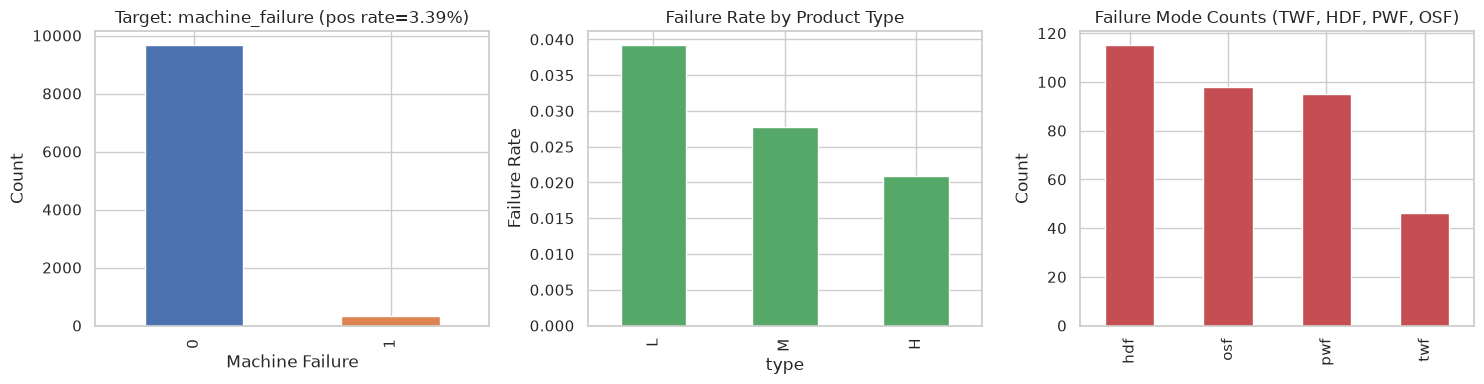

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Target distribution
df[TARGET_COL].value_counts().plot(kind="bar", ax=axes[0], color=["#4c72b0", "#dd8452"])
axes[0].set_title(f"Target: {TARGET_COL} (pos rate={df[TARGET_COL].mean():.2%})")
axes[0].set_xlabel("Machine Failure")
axes[0].set_ylabel("Count")

# Failure rate by machine Type
df.groupby("type")[TARGET_COL].mean().reindex(["L", "M", "H"]).plot(
    kind="bar", ax=axes[1], color="#55a868"
)
axes[1].set_title("Failure Rate by Product Type")
axes[1].set_ylabel("Failure Rate")

# Failure mode counts
df[MODE_COLS].sum().sort_values(ascending=False).plot(kind="bar", ax=axes[2], color="#c44e52")
axes[2].set_title("Failure Mode Counts (TWF, HDF, PWF, OSF)")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

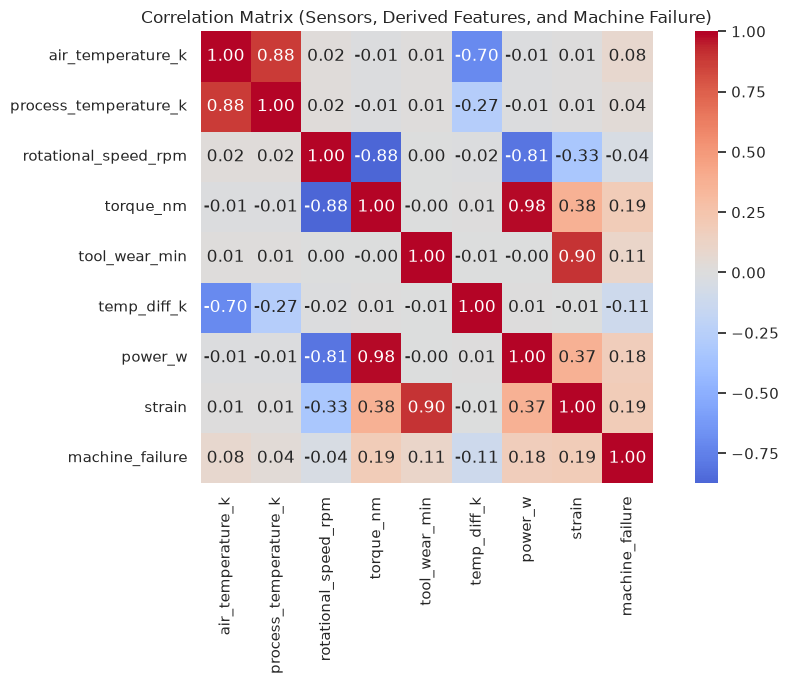

In [8]:
# Feature distributions and correlation heatmap (including derived physical features)
df_feat = add_features(df)
num_cols = [
    "air_temperature_k",
    "process_temperature_k",
    "rotational_speed_rpm",
    "torque_nm",
    "tool_wear_min",
    "temp_diff_k",
    "power_w",
    "strain",
    TARGET_COL,
]

plt.figure(figsize=(10, 7))
corr = df_feat[num_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Matrix (Sensors, Derived Features, and Machine Failure)")
plt.tight_layout()
plt.show()

## 3. Stratified 60/20/20 Split, Mutual Information & Feature Ablation

In [9]:
splits = split_dataset(df, seed=SEED)
print(
    f"Train: {len(splits.X_train)} (pos={splits.y_train.mean():.2%}) | "
    f"Val: {len(splits.X_val)} (pos={splits.y_val.mean():.2%}) | "
    f"Test: {len(splits.X_test)} (pos={splits.y_test.mean():.2%})"
)

Train: 6000 (pos=3.38%) | Val: 2000 (pos=3.40%) | Test: 2000 (pos=3.40%)


In [10]:
# Mutual information on training split (raw + derived numeric features)
X_train_feat = add_features(splits.X_train)
mi_cols = [
    "air_temperature_k",
    "process_temperature_k",
    "rotational_speed_rpm",
    "torque_nm",
    "tool_wear_min",
    "temp_diff_k",
    "power_w",
    "strain",
]
mi_scores = mutual_info_classif(X_train_feat[mi_cols], splits.y_train, random_state=SEED)
mi_series = pd.Series(mi_scores, index=mi_cols).sort_values(ascending=False)
print("Mutual Information with machine_failure (train):")
print(mi_series.round(4))

Mutual Information with machine_failure (train):
power_w                  0.0490
torque_nm                0.0455
rotational_speed_rpm     0.0372
strain                   0.0351
temp_diff_k              0.0119
tool_wear_min            0.0107
air_temperature_k        0.0084
process_temperature_k    0.0071
dtype: float64


In [11]:
# Measure PR-AUC gain from adding domain-informed derived features (temp_diff_k, power_w, strain)
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from pdm.config import CATEGORICAL_COLS

cv = StratifiedKFold(n_splits=3 if FAST else 5, shuffle=True, random_state=SEED)
raw_num_cols = [
    "air_temperature_k",
    "process_temperature_k",
    "rotational_speed_rpm",
    "torque_nm",
    "tool_wear_min",
]
raw_pre = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_COLS),
        ("num", StandardScaler(), raw_num_cols),
    ],
    remainder="drop",
)
raw_pipe = Pipeline([("preprocess", raw_pre), ("model", LogisticRegression(max_iter=1000, random_state=SEED))])
feat_pipe = build_pipeline(LogisticRegression(max_iter=1000, random_state=SEED))

raw_pr = cross_val_score(raw_pipe, splits.X_train, splits.y_train, cv=cv, scoring="average_precision").mean()
feat_pr = cross_val_score(feat_pipe, splits.X_train, splits.y_train, cv=cv, scoring="average_precision").mean()
print(f"CV PR-AUC (LogReg) | Raw features: {raw_pr:.4f} | +Derived features: {feat_pr:.4f} (delta={feat_pr - raw_pr:+.4f})")

CV PR-AUC (LogReg) | Raw features: 0.4721 | +Derived features: 0.4991 (delta=+0.0270)


## 4. Model Comparison, Hyperparameter Tuning, Thresholding & Multi-Label

In [12]:
# Run the shared training & evaluation pipeline (LogReg, RF, XGBoost, LightGBM + MultiOutputClassifier)
import tempfile
from pathlib import Path

with tempfile.TemporaryDirectory() as tmpdir:
    tmp_model = Path(tmpdir) / "model.bin"
    tmp_metrics = Path(tmpdir) / "metrics.json"
    metrics = train_and_evaluate(
        data_path=DATA_PATH,
        model_path=tmp_model,
        metrics_path=tmp_metrics,
        fast=bool(FAST),
        seed=SEED,
    )

comp_rows = []
for name, info in metrics["candidates_cv"].items():
    comp_rows.append(
        {
            "model": name,
            "cv_pr_auc": info["cv_pr_auc"],
            "val_pr_auc": info["val_pr_auc"],
            "val_roc_auc": info["val_roc_auc"],
            "fit_seconds": info["fit_seconds"],
        }
    )
comp_df = pd.DataFrame(comp_rows).sort_values("cv_pr_auc", ascending=False)
print(f"Winner: {metrics['winner']} | Threshold: {metrics['threshold']}")
comp_df

Winner: random_forest | Threshold: 0.14


,model,cv_pr_auc,val_pr_auc,val_roc_auc,fit_seconds
1,random_forest,0.909736,0.862969,0.977127,75.391
2,xgboost,0.898257,0.845706,0.982915,9.229
3,lightgbm,0.894830,0.860327,0.982291,12.886
0,logreg,0.499543,0.469185,0.907898,2.128


In [13]:
# Permutation importance on validation set for the winning model
winner_name = metrics["winner"]
pos = int((splits.y_train == 1).sum())
neg = int((splits.y_train == 0).sum())
candidates = get_model_candidates(seed=SEED, scale_pos_weight=float(neg / max(pos, 1)))
winner_estimator, _ = candidates[winner_name]
winner_pipe = build_pipeline(winner_estimator)
winner_params = metrics["candidates_cv"][winner_name]["best_params"]
winner_pipe.set_params(**winner_params)
winner_pipe.fit(splits.X_train, splits.y_train)

perm = permutation_importance(
    winner_pipe,
    splits.X_val,
    splits.y_val,
    scoring="average_precision",
    n_repeats=5 if FAST else 10,
    random_state=SEED,
)
perm_df = pd.DataFrame(
    {"feature": RAW_FEATURE_COLS, "importance_mean": perm.importances_mean, "importance_std": perm.importances_std}
).sort_values("importance_mean", ascending=False)
perm_df

,feature,importance_mean,importance_std
4,torque_nm,0.763055,0.008781
3,rotational_speed_rpm,0.420680,0.018323
5,tool_wear_min,0.334291,0.024895
1,air_temperature_k,0.295885,0.024292
2,process_temperature_k,0.192252,0.010443
0,type,0.055737,0.018402


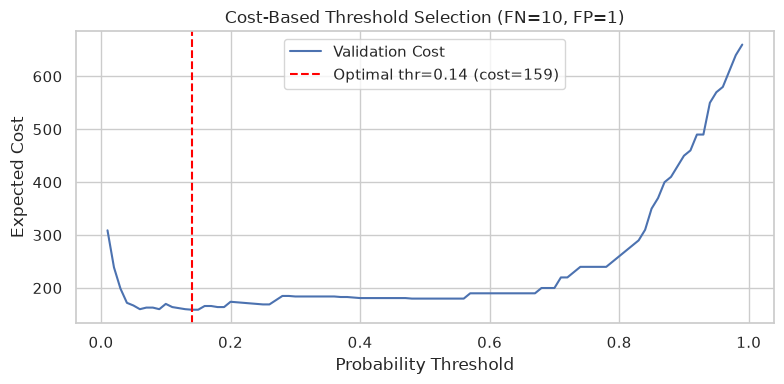

In [14]:
# Cost-based threshold curve on validation set
val_probs = winner_pipe.predict_proba(splits.X_val)[:, 1]
thr_grid = np.linspace(0.01, 0.99, 99)
costs = [
    binary_metrics(splits.y_val, val_probs, threshold=float(t), cost_fn=COST_FN, cost_fp=COST_FP)["cost"]
    for t in thr_grid
]
best_thr, best_cost = choose_threshold(splits.y_val, val_probs, cost_fn=COST_FN, cost_fp=COST_FP)

plt.figure(figsize=(8, 4))
plt.plot(thr_grid, costs, label="Validation Cost")
plt.axvline(best_thr, color="red", linestyle="--", label=f"Optimal thr={best_thr:.2f} (cost={best_cost:.0f})")
plt.title(f"Cost-Based Threshold Selection (FN={COST_FN:.0f}, FP={COST_FP:.0f})")
plt.xlabel("Probability Threshold")
plt.ylabel("Expected Cost")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Final Single Evaluation on Held-Out Test Set

In [15]:
tb = metrics["test_binary"]
tm = metrics["test_modes"]

print("=== Test Set — Binary Machine Failure ===")
for k, v in tb.items():
    print(f"  {k}: {v:.4f}")

print(f"\n=== Test Set — Multi-Label Failure Modes (macro PR-AUC={tm['macro_pr_auc']:.4f}, mean prevalence={tm['mean_prevalence']:.4f}) ===")
pd.DataFrame(tm["per_mode"]).T

=== Test Set — Binary Machine Failure ===
  pr_auc: 0.8937
  roc_auc: 0.9814
  f1: 0.7838
  precision: 0.7250
  recall: 0.8529
  cost: 122.0000

=== Test Set — Multi-Label Failure Modes (macro PR-AUC=0.7667, mean prevalence=0.0085) ===


,pr_auc,recall,prevalence
twf,0.085995,0.000000,0.0050
hdf,0.980925,0.862069,0.0145
pwf,1.000000,1.000000,0.0065
osf,1.000000,1.000000,0.0080


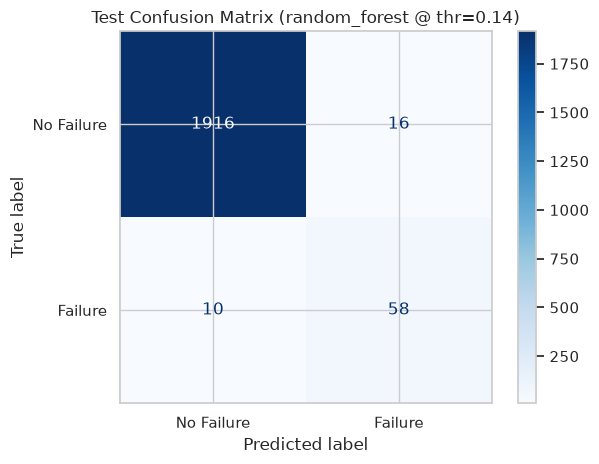

In [16]:
# Confusion matrix on held-out test set
test_probs = winner_pipe.predict_proba(splits.X_test)[:, 1]
test_preds = (test_probs >= metrics["threshold"]).astype(int)
cm = confusion_matrix(splits.y_test, test_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Failure", "Failure"])
disp.plot(cmap="Blues")
plt.title(f"Test Confusion Matrix ({metrics['winner']} @ thr={metrics['threshold']})")
plt.tight_layout()
plt.show()

## 6. Conclusions

- **Derived physical features** (`temp_diff_k`, `power_w`, `strain`) capture the physical mechanisms behind heat dissipation, power, and overstrain failures.
- **Cost-sensitive thresholding** ($\text{FN} = 10 \times \text{FP}$) shifts the operating point below 0.50 to prioritize catching true machine failures.
- **Multi-label failure mode prediction** provides actionable diagnostics (`likely_modes`) whenever a failure is predicted.
- The production bundle is trained via `train.py` and served via `predict.py` (FastAPI + Docker).